<a href="https://colab.research.google.com/github/fawaztanigbola/Nigeria-ForeCasting-Model/blob/main/Geospatial_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Southwest Nigeria Temperature Forecasting – Geospatial LSTM

## Overview
Extended the baseline LSTM temperature forecasting model by incorporating geographical and seasonal information to investigate whether spatial context improves next-day temperature predictions.

The model forecasts daily minimum and maximum temperatures across Lagos, Ogun, Oyo, and Osun states using ERA5 data from 2015–2024.

## Dataset
- 3,653 daily observations (2015–2024).
- Original grid: 28 × 24 (672 grid cells).
- 456 valid geographical locations retained after removing cells with entirely missing temperature observations.
- Temperature variables: Minimum temperature (Tmin) and maximum temperature (Tmax).
- Elevation extracted from the regional elevation dataset (0–544.1 m).
- Remaining temperature gaps filled using linear interpolation along the time dimension.

## Model Inputs
The model combines temporal and static geographical information.

**Temporal features:**
- Minimum temperature (Tmin).
- Maximum temperature (Tmax).
- Day-of-year sine.
- Day-of-year cosine.

**Static geographical features:**
- Latitude.
- Longitude.
- Elevation.

The temporal features are processed by the LSTM, while geographical features are concatenated with the final LSTM representation before the prediction layers.

## Data Preparation
- Training: 2015–2021.
- Validation: 2022.
- Testing: 2023–2024.
- Temperature features scaled using MinMaxScaler fitted on training data.
- Geographical features independently scaled.
- Seasonal features encoded using sine and cosine transformations.

## Model Architecture
- Architecture: Single-layer LSTM with a fully connected prediction head.
- Input sequence features: 4.
- Static geographical features: 3.
- Hidden size: 64.
- Output size: 2 (Tmin and Tmax).
- Optimizer: Adam.
- Learning rate: 0.001.
- Loss function: Mean Squared Error (MSE).
- Gradient clipping: Maximum norm of 1.0.
- Mixed-precision training enabled.
- Hardware: NVIDIA Tesla T4 GPU.

## Experiments

Three investigations were conducted:

1. **Input window length:** Compared 7, 14 and 30 days. Seven days achieved the best validation RMSE.
2. **Architecture and regularization:** Compared one and two LSTM layers, with dropout configurations of 0.0 and 0.2. The single-layer model without dropout performed best on validation.
3. **Geographical feature ablation:** Compared the model with latitude, longitude and elevation against a version without these static features.

The geographical feature ablation did not demonstrate an improvement in overall test performance.

## Geospatial LSTM Test Results

| Metric | Tmin | Tmax |
|---|---:|---:|
| MAE | 0.535°C | 1.021°C |
| RMSE | 0.707°C | 1.346°C |

## Comparison with the Baseline LSTM

The original temperature-only LSTM achieved:

| Metric | Baseline LSTM | Geospatial LSTM |
|---|---:|---:|
| Tmin MAE | **0.502°C** | 0.535°C |
| Tmin RMSE | **0.690°C** | 0.707°C |
| Tmax MAE | **0.988°C** | 1.021°C |
| Tmax RMSE | **1.324°C** | 1.346°C |

The original baseline LSTM achieved better results across all four metrics.

**Important:** The two notebooks use different normalization approaches and their chronological test splits have not yet been confirmed to match. The comparison is therefore indicative rather than a strictly controlled head-to-head evaluation.

## Comparison Against Other Forecasting Baselines

On the geospatial experiment's own test period, the geospatial LSTM also outperformed:

- **Persistence baseline:** using the previous day's temperature as the prediction.
- **Day-of-year climatology:** using historical average temperatures for the corresponding day of the year.

This demonstrates that the geospatial experiment learned useful predictive temperature patterns, even though adding static geographical features did not improve upon the original LSTM.

## Key Findings and Limitations

- Seven-day input windows performed best during validation.
- Additional LSTM layers and dropout did not improve validation performance.
- Adding latitude, longitude and elevation did not improve overall test metrics in the feature ablation.
- The original temperature-only LSTM remains the better-performing model based on the available results.
- The experiment uses ERA5 grid-level data and should not be interpreted as street-level temperature forecasting.
- The current geographical features may not fully capture local terrain, land cover and urban temperature variations.


Importing Libraries.

In [10]:
import math, copy, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

project_dir = Path("/content/drive/MyDrive/Nigeria_Temperature_Project")
regional_file = project_dir / "processed" / "southwest_4states_daily_2015_2024.nc"
OUT_DIR = project_dir / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

QUICK_TEST = False            # True -> 2 epochs per run, to smoke-test the notebook
SEED = 42
EPOCHS = 2 if QUICK_TEST else 18
LR, CLIP, BATCH, HIDDEN = 1e-3, 1.0, 1024, 64
S_VALUES = [7, 14, 30]
VAL_START, TEST_START = "2022-01-01", "2023-01-01"   # train: 2015-2021, val: 2022, test: 2023-2024
LAGOS = (6.52, 3.39)          # (lat, lon)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, "| AMP:", USE_AMP)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | AMP: True


In [11]:
ds = xr.open_dataset(regional_file)
assert {"tmin", "tmax", "elevation"} <= set(ds.data_vars), "Expected variables: tmin, tmax, elevation"
if "valid_time" in ds.dims:
    ds = ds.rename({"valid_time": "time"})
ds = ds.drop_vars("number", errors="ignore").sortby("time").sortby("latitude").load()

# Mask GRIB missing values, K -> degC
for v in ["tmin", "tmax"]:
    da = ds[v].transpose("time", "latitude", "longitude")
    da = da.where(da < 1e30)
    if float(da.mean()) > 200:
        da = da - 273.15
    ds[v] = da

# Sanity checks
t = ds["time"].to_index()
assert t.is_monotonic_increasing, "Time must be sorted ascending"
assert t.is_unique, "Duplicate timestamps"
missing_days = pd.date_range(t[0], t[-1], freq="D").difference(t)
assert len(missing_days) == 0, f"Missing days: {len(missing_days)}"

T = len(t)
nlat, nlon = ds.sizes["latitude"], ds.sizes["longitude"]
lat_vals, lon_vals = ds["latitude"].values, ds["longitude"].values

tmin_all = ds["tmin"].values.reshape(T, -1).astype(np.float32)
tmax_all = ds["tmax"].values.reshape(T, -1).astype(np.float32)
elev_all = ds["elevation"].transpose("latitude", "longitude").values.reshape(-1).astype(np.float32)

print(f"Days: {T} ({t[0].date()} -> {t[-1].date()}) | grid: {nlat} x {nlon}")
print("NaNs  tmin/tmax:", int(np.isnan(tmin_all).sum()), int(np.isnan(tmax_all).sum()))
print(f"tmin range: {np.nanmin(tmin_all):.1f} .. {np.nanmax(tmin_all):.1f} C | "
      f"tmax range: {np.nanmin(tmax_all):.1f} .. {np.nanmax(tmax_all):.1f} C")
print(f"Elevation range: {np.nanmin(elev_all):.1f} .. {np.nanmax(elev_all):.1f}")
print(f"Days with tmax < tmin: {float(np.nanmean(tmax_all < tmin_all)) * 100:.3f}%")

# Drop cells that are entirely NaN (e.g. ocean)
bad = np.isnan(tmin_all).all(0) | np.isnan(tmax_all).all(0)
valid_idx = np.where(~bad)[0]
print(f"Grid cells: {nlat * nlon} | dropped (all-NaN): {int(bad.sum())} | kept: {len(valid_idx)}")

# Interpolate small gaps along time (linear, both directions), like the CSV notebook
def fill_gaps(a):
    return pd.DataFrame(a).interpolate(method="linear", limit_direction="both").to_numpy(np.float32)

nan_before = int(np.isnan(tmin_all[:, valid_idx]).sum() + np.isnan(tmax_all[:, valid_idx]).sum())
tmin_v = fill_gaps(tmin_all[:, valid_idx])
tmax_v = fill_gaps(tmax_all[:, valid_idx])
nan_after = int(np.isnan(tmin_v).sum() + np.isnan(tmax_v).sum())
print(f"Missing values before: {nan_before} | after interpolation: {nan_after}")

cell_i, cell_j = np.unravel_index(valid_idx, (nlat, nlon))
cell_lat, cell_lon = lat_vals[cell_i], lon_vals[cell_j]
cell_elev = elev_all[valid_idx]
if np.isnan(cell_elev).any():
    print("Filling", int(np.isnan(cell_elev).sum()), "NaN elevation values with the mean")
    cell_elev = np.where(np.isnan(cell_elev), np.nanmean(cell_elev), cell_elev).astype(np.float32)

N = len(valid_idx)
DATA_C = np.stack([tmin_v, tmax_v], axis=-1).astype(np.float32)   # (T, N, 2) in degC

Days: 3653 (2015-01-01 -> 2024-12-31) | grid: 28 x 24
NaNs  tmin/tmax: 789048 789048
tmin range: 14.7 .. 28.8 C | tmax range: 21.3 .. 41.2 C
Elevation range: 0.0 .. 544.1
Days with tmax < tmin: 0.000%
Grid cells: 672 | dropped (all-NaN): 216 | kept: 456
Missing values before: 0 | after interpolation: 0


In [12]:
i_val = int(t.searchsorted(pd.Timestamp(VAL_START)))
i_test = int(t.searchsorted(pd.Timestamp(TEST_START)))
n_val, n_test = i_test - i_val, T - i_test
print(f"Train: {t[0].date()} -> {t[i_val-1].date()} ({i_val} days)")
print(f"Val  : {t[i_val].date()} -> {t[i_test-1].date()} ({n_val} days)")
print(f"Test : {t[i_test].date()} -> {t[-1].date()} ({n_test} days)")

# Scaling: fit on TRAIN period only
scaler_y = MinMaxScaler().fit(DATA_C[:i_val].reshape(-1, 2))        # one min/max per variable (tmin, tmax)
Y_sc = scaler_y.transform(DATA_C.reshape(-1, 2)).reshape(T, N, 2).astype(np.float32)

static_np = np.stack([cell_lat, cell_lon, cell_elev], axis=1).astype(np.float32)   # (N, 3)
scaler_static = MinMaxScaler().fit(static_np)
static_sc = scaler_static.transform(static_np).astype(np.float32)

print("Scaled ranges (tmin, tmax):")
for name, sl in [("Train", slice(0, i_val)), ("Val", slice(i_val, i_test)), ("Test", slice(i_test, T))]:
    print(f"  {name:5s}: {float(Y_sc[sl].min()):.3f} -> {float(Y_sc[sl].max()):.3f}")

# Day-of-year seasonality features (known in advance, no leakage)
doy = t.dayofyear.values
ang = 2 * np.pi * doy / 365.25
doy_feat = np.stack([np.sin(ang), np.cos(ang)], axis=-1).astype(np.float32)       # (T, 2)
seq_np = np.concatenate([Y_sc, np.broadcast_to(doy_feat[:, None, :], (T, N, 2))], axis=-1)  # (T, N, 4)

SEQ = torch.tensor(seq_np, dtype=torch.float32, device=DEVICE)       # per-timestep inputs
Y = torch.tensor(Y_sc, dtype=torch.float32, device=DEVICE)           # targets (scaled)
STATIC = torch.tensor(static_sc, dtype=torch.float32, device=DEVICE) # lat, lon, elevation

TRUE_VAL = DATA_C[i_val:i_test]    # degC ground truth
TRUE_TEST = DATA_C[i_test:]

class WindowLoader:
    """Lazy single-step windows on the GPU. A sample = (day t, grid cell n):
    inputs = days t-S..t-1 of that cell, target = day t (tmin, tmax)."""
    def __init__(self, S, t_lo, t_hi, batch_size, shuffle=False, n_sample=None, seed=0):
        assert t_lo >= S, "Not enough history for the first window"
        self.S, self.t_lo, self.bs, self.shuffle = S, t_lo, batch_size, shuffle
        self.offs = torch.arange(-S, 0, device=DEVICE)
        total = (t_hi - t_lo) * N
        if n_sample is not None and n_sample < total:
            g = torch.Generator().manual_seed(seed)
            self.pairs = torch.sort(torch.randperm(total, generator=g)[:n_sample]).values.to(DEVICE)
        else:
            self.pairs = torch.arange(total, device=DEVICE)

    def __len__(self):
        return math.ceil(len(self.pairs) / self.bs)

    def __iter__(self):
        pairs = self.pairs[torch.randperm(len(self.pairs), device=DEVICE)] if self.shuffle else self.pairs
        for i in range(0, len(pairs), self.bs):
            p = pairs[i:i + self.bs]
            tt = self.t_lo + p // N
            nn_ = p % N
            idx = tt[:, None] + self.offs[None, :]            # (B, S)
            yield SEQ[idx, nn_[:, None]], STATIC[nn_], Y[tt, nn_]   # (B,S,4), (B,3), (B,2)

def make_loaders(S):
    return {
        "train":      WindowLoader(S, S, i_val, BATCH, shuffle=True),
        "train_eval": WindowLoader(S, S, i_val, 4096, n_sample=200_000, seed=0),
        "val":        WindowLoader(S, i_val, i_test, 4096),
        "test":       WindowLoader(S, i_test, T, 4096),
    }

print("Train windows (S=30):", (i_val - 30) * N, "| val:", n_val * N, "| test:", n_test * N)

Train: 2015-01-01 -> 2021-12-31 (2557 days)
Val  : 2022-01-01 -> 2022-12-31 (365 days)
Test : 2023-01-01 -> 2024-12-31 (731 days)
Scaled ranges (tmin, tmax):
  Train: 0.000 -> 1.000
  Val  : 0.017 -> 0.982
  Test : 0.035 -> 1.048
Train windows (S=30): 1152312 | val: 166440 | test: 333336


In [13]:
class LSTMStaticCfg(nn.Module):
    """LSTM over the last S days; optional static features (lat, lon, elev) joined before the head."""
    def __init__(self, seq_in=4, static_in=3, hidden_size=64, num_layers=1, dropout=0.0, use_static=True, out=2):
        super().__init__()
        self.use_static = use_static
        self.lstm = nn.LSTM(seq_in, hidden_size, num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        head_in = hidden_size + (static_in if use_static else 0)
        self.head = nn.Sequential(nn.Linear(head_in, 32), nn.ReLU(), nn.Linear(32, out))

    def forward(self, x, s):
        out, _ = self.lstm(x)               # h0/c0 default to zeros; out: (B, S, H)
        h = self.drop(out[:, -1, :])        # (B, H)
        if self.use_static:
            h = torch.cat([h, s.to(h.dtype)], dim=1)
        return self.head(h)                 # (B, 2) scaled [tmin, tmax]

def build_model(layers, dropout, use_static=True):
    return LSTMStaticCfg(seq_in=SEQ.shape[-1], static_in=STATIC.shape[-1], hidden_size=HIDDEN,
                         num_layers=layers, dropout=dropout, use_static=use_static)

criterion = nn.MSELoss()

def mae(a, b):  return float(np.mean(np.abs(a - b)))
def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))

def compute_metrics(y_true, y_pred, prefix):
    out = {}
    for j, name in enumerate(["tmin", "tmax"]):
        out[f"{prefix}_MAE_{name}"] = mae(y_true[..., j], y_pred[..., j])
        out[f"{prefix}_RMSE_{name}"] = rmse(y_true[..., j], y_pred[..., j])
    out[f"{prefix}_MAE_C"] = (out[f"{prefix}_MAE_tmin"] + out[f"{prefix}_MAE_tmax"]) / 2
    out[f"{prefix}_RMSE_C"] = (out[f"{prefix}_RMSE_tmin"] + out[f"{prefix}_RMSE_tmax"]) / 2
    return out

@torch.no_grad()
def eval_mse_scaled(model, loader):
    model.eval()
    tot, n = 0.0, 0
    for xb, sb, yb in loader:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            yhat = model(xb, sb)
        loss = criterion(yhat.float(), yb)
        tot += loss.item() * xb.size(0); n += xb.size(0)
    return tot / max(n, 1)

@torch.no_grad()
def predict_scaled(model, loader):
    model.eval()
    preds = []
    for xb, sb, _ in loader:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            yhat = model(xb, sb)
        preds.append(yhat.float().cpu())
    return torch.cat(preds).numpy()          # (n_days * N, 2) scaled

def to_C(pred_sc, n_days):
    return scaler_y.inverse_transform(pred_sc).reshape(n_days, N, 2)   # (n_days, N, 2) degC

def train_eval_config(model, label, S, epochs=EPOCHS, lr=LR, clip=CLIP):
    """Train one config; keep the best epoch by val MSE; return curves + val/test metrics in degC."""
    model = model.to(DEVICE)
    loaders = make_loaders(S)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    amp_scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    tr_hist, va_hist = [], []
    best_va, best_ep, best_state = float("inf"), 0, None
    t0 = time.time()

    for ep in range(1, epochs + 1):
        model.train()
        for xb, sb, yb in loaders["train"]:
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                yhat = model(xb, sb)
            loss = criterion(yhat.float(), yb)
            amp_scaler.scale(loss).backward()
            amp_scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            amp_scaler.step(opt)
            amp_scaler.update()

        tr_mse = eval_mse_scaled(model, loaders["train_eval"])
        va_mse = eval_mse_scaled(model, loaders["val"])
        tr_hist.append(tr_mse); va_hist.append(va_mse)
        if va_mse < best_va:
            best_va, best_ep = va_mse, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if ep in (1, 6, 12, epochs):
            print(f"[{label} | ep {ep:02d}] train MSE={tr_mse:.5f} | val MSE={va_mse:.5f} | {time.time()-t0:.0f}s")

    model.load_state_dict(best_state)
    print(f"[{label}] best epoch = {best_ep} (val MSE={best_va:.5f})")

    pv = to_C(predict_scaled(model, loaders["val"]), n_val)
    pt = to_C(predict_scaled(model, loaders["test"]), n_test)
    metrics = {**compute_metrics(TRUE_VAL, pv, "Val"), **compute_metrics(TRUE_TEST, pt, "Test")}
    return tr_hist, va_hist, metrics, best_ep, best_state

RUNS = {}   # cache: (S, layers, dropout, use_static) -> results (avoids retraining the same config)

def run_config(S, layers, dropout, use_static=True):
    key = (S, layers, dropout, use_static)
    if key in RUNS:
        return RUNS[key]
    label = f"LSTM-S{S}-L{layers}-do{dropout}" + ("" if use_static else "-nostatic")
    set_seed(SEED)
    model = build_model(layers, dropout, use_static)
    tr, va, m, best_ep, state = train_eval_config(model, label, S)
    RUNS[key] = {"label": label, "tr": tr, "va": va, "metrics": m, "best_ep": best_ep,
                 "state": {k: v.cpu() for k, v in state.items()}}
    return RUNS[key]

In [14]:
rows_A, curves_A = [], {}
for S in S_VALUES:
    r = run_config(S, layers=1, dropout=0.0, use_static=True)
    curves_A[S] = (r["tr"], r["va"])
    rows_A.append({"S": S, "BestEpoch": r["best_ep"], **r["metrics"]})

df_S = pd.DataFrame(rows_A).set_index("S").sort_values("Val_RMSE_C")
BEST_S = int(df_S.index[0])
print(f"\nBest S by Val_RMSE_C: {BEST_S}")
display(df_S[["Val_MAE_C", "Val_RMSE_C", "Test_MAE_C", "Test_RMSE_C", "BestEpoch"]])

/tmp/ipykernel_800/3732311730.py:66: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


[LSTM-S7-L1-do0.0 | ep 01] train MSE=0.00352 | val MSE=0.00419 | 8s
[LSTM-S7-L1-do0.0 | ep 06] train MSE=0.00328 | val MSE=0.00405 | 34s
[LSTM-S7-L1-do0.0 | ep 12] train MSE=0.00315 | val MSE=0.00398 | 65s
[LSTM-S7-L1-do0.0 | ep 18] train MSE=0.00298 | val MSE=0.00414 | 96s
[LSTM-S7-L1-do0.0] best epoch = 13 (val MSE=0.00393)


/tmp/ipykernel_800/3732311730.py:66: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


[LSTM-S14-L1-do0.0 | ep 01] train MSE=0.00354 | val MSE=0.00420 | 5s
[LSTM-S14-L1-do0.0 | ep 06] train MSE=0.00326 | val MSE=0.00406 | 31s
[LSTM-S14-L1-do0.0 | ep 12] train MSE=0.00310 | val MSE=0.00404 | 62s
[LSTM-S14-L1-do0.0 | ep 18] train MSE=0.00260 | val MSE=0.00477 | 94s
[LSTM-S14-L1-do0.0] best epoch = 7 (val MSE=0.00396)


/tmp/ipykernel_800/3732311730.py:66: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


[LSTM-S30-L1-do0.0 | ep 01] train MSE=0.00360 | val MSE=0.00416 | 5s
[LSTM-S30-L1-do0.0 | ep 06] train MSE=0.00325 | val MSE=0.00399 | 31s
[LSTM-S30-L1-do0.0 | ep 12] train MSE=0.00297 | val MSE=0.00418 | 63s
[LSTM-S30-L1-do0.0 | ep 18] train MSE=0.00238 | val MSE=0.00511 | 98s
[LSTM-S30-L1-do0.0] best epoch = 6 (val MSE=0.00399)

Best S by Val_RMSE_C: 7


,Val_MAE_C,Val_RMSE_C,Test_MAE_C,Test_RMSE_C,BestEpoch
S,,,,,
7,0.747997,1.037618,0.777945,1.026826,13
14,0.749229,1.040953,0.766792,1.015760,7
30,0.754086,1.044826,0.759553,1.012090,6


In [15]:
grid = [(layers, dropout) for layers in [1, 2] for dropout in [0.0, 0.2]]
curves_B, rows_B = {}, []
best_val_rmseC, best_cfg = float("inf"), None

for layers, dropout in grid:
    r = run_config(BEST_S, layers, dropout, use_static=True)
    label = f"LSTM-L{layers}-do{dropout}"
    curves_B[label] = (r["tr"], r["va"])
    rows_B.append({"Layers": layers, "Dropout": dropout, "BestEpoch": r["best_ep"], **r["metrics"]})
    if r["metrics"]["Val_RMSE_C"] < best_val_rmseC:
        best_val_rmseC = r["metrics"]["Val_RMSE_C"]
        best_cfg = (layers, dropout)
        print(f"New best model: {label} with Val_RMSE_C={best_val_rmseC:.3f}")

df_B = pd.DataFrame(rows_B)
df_B_sorted = df_B.sort_values(["Val_RMSE_C", "Val_MAE_C"], ascending=[True, True]).reset_index(drop=True)
BEST_LAYERS, BEST_DO = best_cfg
display(df_B_sorted[["Layers", "Dropout", "Val_MAE_C", "Val_RMSE_C", "Test_MAE_C", "Test_RMSE_C", "BestEpoch"]])

# Rebuild the best model with its best-epoch weights
best_run = RUNS[(BEST_S, BEST_LAYERS, BEST_DO, True)]
model_best = build_model(BEST_LAYERS, BEST_DO, True).to(DEVICE)
model_best.load_state_dict(best_run["state"])
print(f"Best config: S={BEST_S}, layers={BEST_LAYERS}, dropout={BEST_DO}")

New best model: LSTM-L1-do0.0 with Val_RMSE_C=1.038


/tmp/ipykernel_800/3732311730.py:66: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


[LSTM-S7-L1-do0.2 | ep 01] train MSE=0.00355 | val MSE=0.00426 | 6s
[LSTM-S7-L1-do0.2 | ep 06] train MSE=0.00337 | val MSE=0.00431 | 32s
[LSTM-S7-L1-do0.2 | ep 12] train MSE=0.00336 | val MSE=0.00439 | 63s
[LSTM-S7-L1-do0.2 | ep 18] train MSE=0.00340 | val MSE=0.00463 | 95s
[LSTM-S7-L1-do0.2] best epoch = 2 (val MSE=0.00422)


/tmp/ipykernel_800/3732311730.py:66: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


[LSTM-S7-L2-do0.0 | ep 01] train MSE=0.00350 | val MSE=0.00420 | 8s
[LSTM-S7-L2-do0.0 | ep 06] train MSE=0.00328 | val MSE=0.00405 | 44s
[LSTM-S7-L2-do0.0 | ep 12] train MSE=0.00305 | val MSE=0.00411 | 85s
[LSTM-S7-L2-do0.0 | ep 18] train MSE=0.00245 | val MSE=0.00477 | 125s
[LSTM-S7-L2-do0.0] best epoch = 9 (val MSE=0.00395)


/tmp/ipykernel_800/3732311730.py:66: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


[LSTM-S7-L2-do0.2 | ep 01] train MSE=0.00365 | val MSE=0.00435 | 7s
[LSTM-S7-L2-do0.2 | ep 06] train MSE=0.00333 | val MSE=0.00417 | 41s
[LSTM-S7-L2-do0.2 | ep 12] train MSE=0.00322 | val MSE=0.00425 | 81s
[LSTM-S7-L2-do0.2 | ep 18] train MSE=0.00295 | val MSE=0.00472 | 122s
[LSTM-S7-L2-do0.2] best epoch = 3 (val MSE=0.00409)


,Layers,Dropout,Val_MAE_C,Val_RMSE_C,Test_MAE_C,Test_RMSE_C,BestEpoch
0,1,0.0,0.747997,1.037618,0.777945,1.026826,13
1,2,0.0,0.747392,1.039198,0.766285,1.015858,9
2,2,0.2,0.762388,1.058158,0.761851,1.012145,3
3,1,0.2,0.783369,1.075049,0.791792,1.038479,2


Best config: S=7, layers=1, dropout=0.0


In [16]:
# --- Experiment C: do lat/lon/elevation help? ---
r_static = RUNS[(BEST_S, BEST_LAYERS, BEST_DO, True)]
r_nostat = run_config(BEST_S, BEST_LAYERS, BEST_DO, use_static=False)
df_C = pd.DataFrame([
    {"Features": "with lat/lon/elev", **r_static["metrics"]},
    {"Features": "without static",    **r_nostat["metrics"]},
]).set_index("Features")
display(df_C[["Val_MAE_C", "Val_RMSE_C", "Test_MAE_C", "Test_RMSE_C"]])
print(f"Test RMSE change from static features: "
      f"{df_C.loc['with lat/lon/elev','Test_RMSE_C'] - df_C.loc['without static','Test_RMSE_C']:+.4f} C (negative = better)")

# --- Baselines on the same val/test days ---
pers_val  = DATA_C[i_val - 1:i_test - 1]       # yesterday = tomorrow
pers_test = DATA_C[i_test - 1:T - 1]

train_doy = doy[:i_val]
fallback = DATA_C[:i_val].mean(0)
clim = np.zeros((367, N, 2), dtype=np.float32)
for d in range(1, 367):
    m = train_doy == d
    clim[d] = DATA_C[:i_val][m].mean(0) if m.any() else fallback
clim_val, clim_test = clim[doy[i_val:i_test]], clim[doy[i_test:]]

# --- Best LSTM predictions (degC) ---
loaders = make_loaders(BEST_S)
pred_val_C  = to_C(predict_scaled(model_best, loaders["val"]), n_val)
pred_test_C = to_C(predict_scaled(model_best, loaders["test"]), n_test)

def result_row(name, pv, pt):
    return {"Model": name, **compute_metrics(TRUE_VAL, pv, "Val"), **compute_metrics(TRUE_TEST, pt, "Test")}

df_final = pd.DataFrame([
    result_row(f"LSTM (S={BEST_S}, L{BEST_LAYERS}, do{BEST_DO})", pred_val_C, pred_test_C),
    result_row("Persistence", pers_val, pers_test),
    result_row("Day-of-year climatology", clim_val, clim_test),
]).set_index("Model")
display(df_final[["Val_MAE_tmin", "Val_RMSE_tmin", "Val_MAE_tmax", "Val_RMSE_tmax",
                  "Test_MAE_tmin", "Test_RMSE_tmin", "Test_MAE_tmax", "Test_RMSE_tmax"]].round(3))

/tmp/ipykernel_800/3732311730.py:66: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


[LSTM-S7-L1-do0.0-nostatic | ep 01] train MSE=0.00364 | val MSE=0.00434 | 5s
[LSTM-S7-L1-do0.0-nostatic | ep 06] train MSE=0.00334 | val MSE=0.00410 | 31s
[LSTM-S7-L1-do0.0-nostatic | ep 12] train MSE=0.00320 | val MSE=0.00410 | 63s
[LSTM-S7-L1-do0.0-nostatic | ep 18] train MSE=0.00298 | val MSE=0.00433 | 95s
[LSTM-S7-L1-do0.0-nostatic] best epoch = 9 (val MSE=0.00404)


,Val_MAE_C,Val_RMSE_C,Test_MAE_C,Test_RMSE_C
Features,,,,
with lat/lon/elev,0.747997,1.037618,0.777945,1.026826
without static,0.758612,1.051303,0.746635,1.006270


Test RMSE change from static features: +0.0206 C (negative = better)


,Val_MAE_tmin,Val_RMSE_tmin,Val_MAE_tmax,Val_RMSE_tmax,Test_MAE_tmin,Test_RMSE_tmin,Test_MAE_tmax,Test_RMSE_tmax
Model,,,,,,,,
"LSTM (S=7, L1, do0.0)",0.502,0.688,0.994,1.388,0.535,0.707,1.021,1.346
Persistence,0.581,0.773,1.275,1.810,0.583,0.779,1.144,1.636
Day-of-year climatology,0.795,1.101,1.203,1.636,0.912,1.207,1.378,1.731


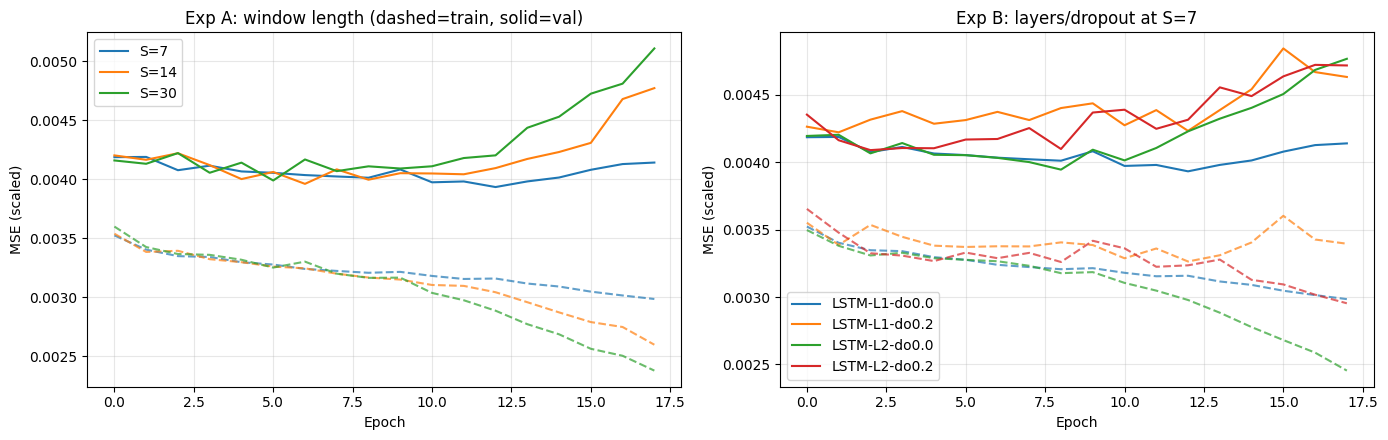

Lagos plot cell: lat=6.50, lon=3.40, elev=0.0


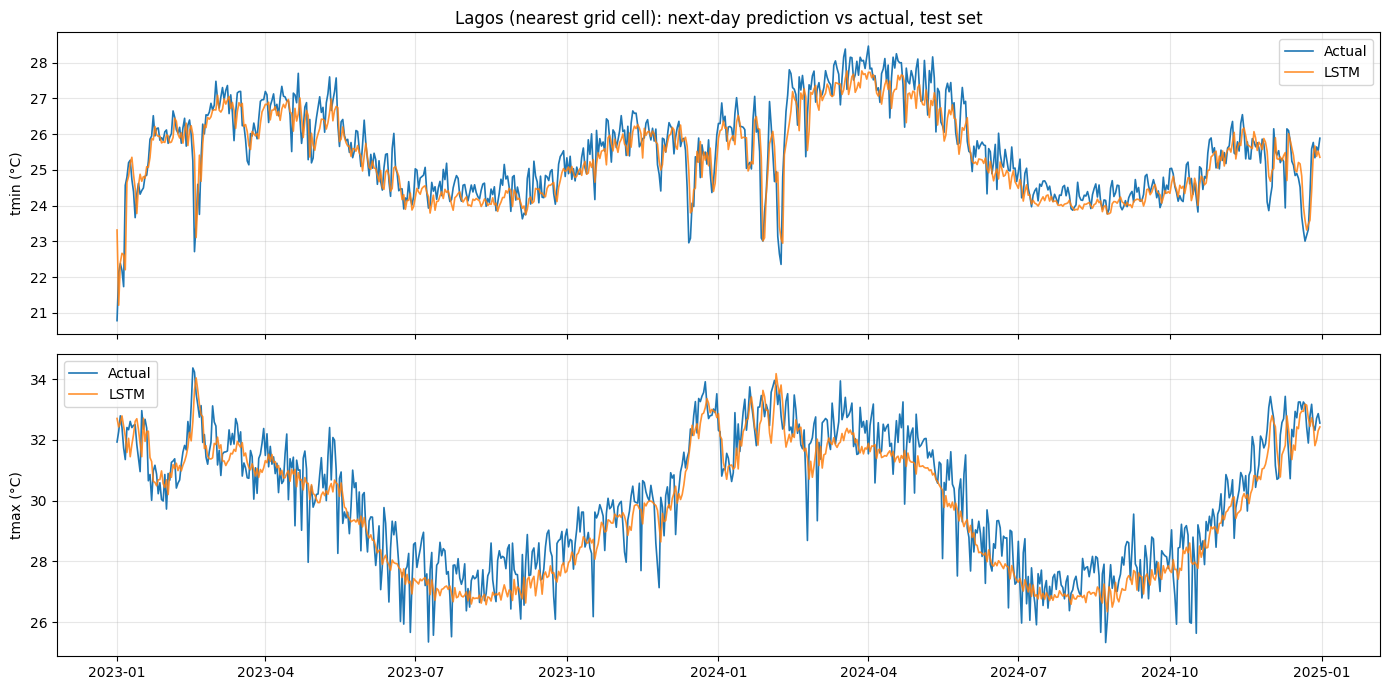

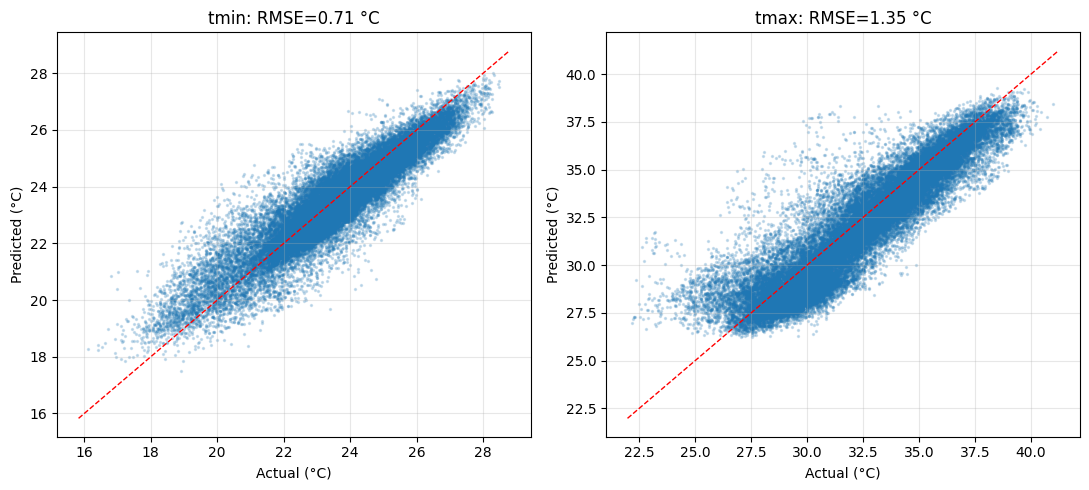

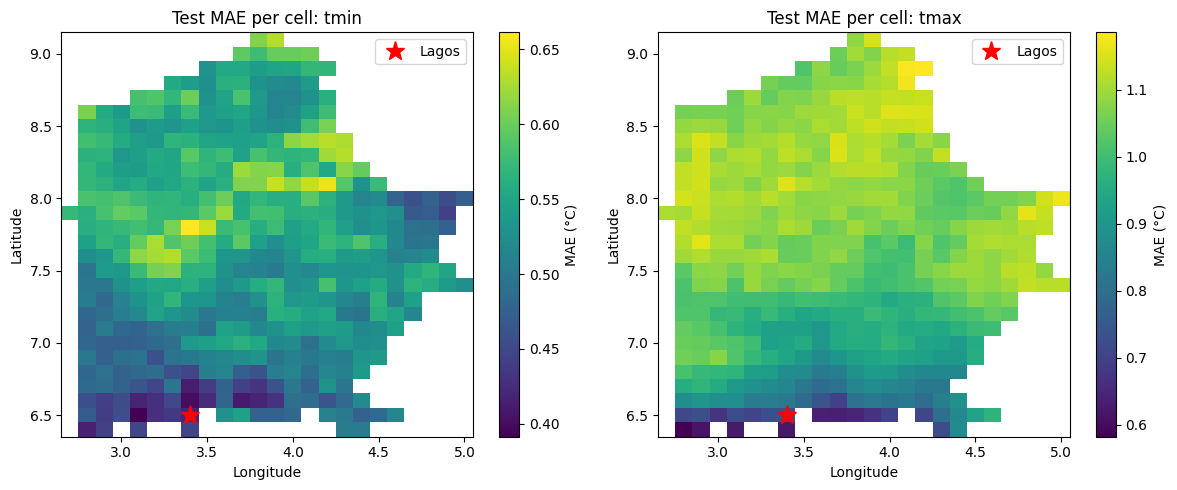

tmin: corr(elevation, MAE) = +0.531
tmax: corr(elevation, MAE) = +0.760


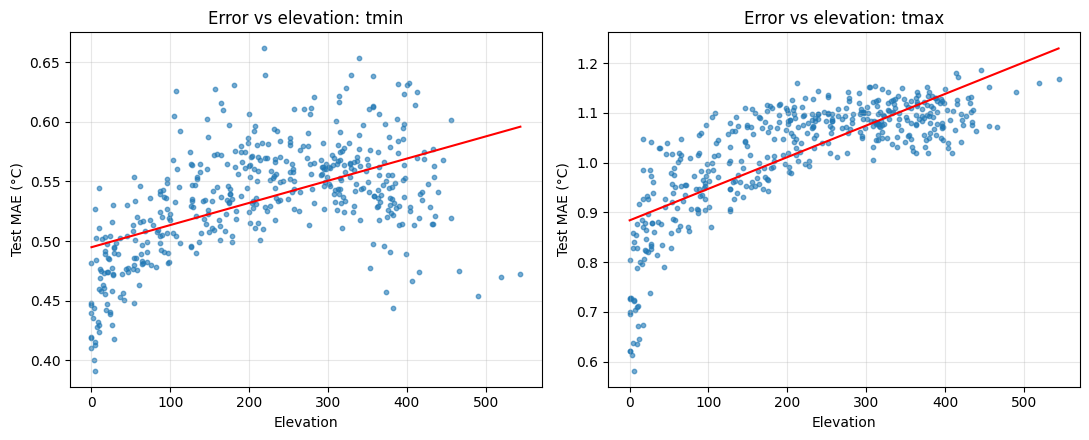

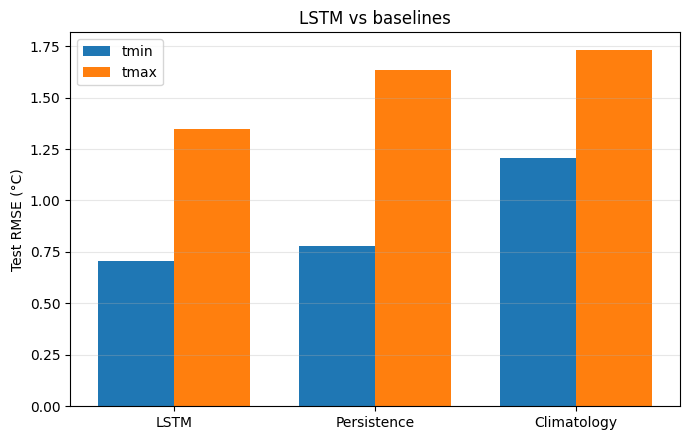

In [17]:
def save_show(name):
    plt.tight_layout()
    plt.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

# 1) Train/val loss curves (scaled MSE): Experiment A and B
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for S, (tr, va) in curves_A.items():
    l, = axes[0].plot(tr, "--", alpha=0.7); axes[0].plot(va, color=l.get_color(), label=f"S={S}")
axes[0].set_title("Exp A: window length (dashed=train, solid=val)")
for lab, (tr, va) in curves_B.items():
    l, = axes[1].plot(tr, "--", alpha=0.7); axes[1].plot(va, color=l.get_color(), label=lab)
axes[1].set_title(f"Exp B: layers/dropout at S={BEST_S}")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (scaled)"); ax.legend(); ax.grid(alpha=0.3)
save_show("loss_curves.png")

# 2) Lagos time series (test set)
d2 = (cell_lat - LAGOS[0]) ** 2 + (cell_lon - LAGOS[1]) ** 2
lagos_n = int(d2.argmin())
print(f"Lagos plot cell: lat={cell_lat[lagos_n]:.2f}, lon={cell_lon[lagos_n]:.2f}, elev={cell_elev[lagos_n]:.1f}")
test_dates = t[i_test:]
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for j, name in enumerate(["tmin", "tmax"]):
    axes[j].plot(test_dates, TRUE_TEST[:, lagos_n, j], label="Actual", lw=1.2)
    axes[j].plot(test_dates, pred_test_C[:, lagos_n, j], label="LSTM", lw=1.2, alpha=0.85)
    axes[j].set_ylabel(f"{name} (°C)"); axes[j].legend(); axes[j].grid(alpha=0.3)
axes[0].set_title("Lagos (nearest grid cell): next-day prediction vs actual, test set")
save_show("lagos_timeseries.png")

# 3) Predicted vs actual scatter (test, random 40k samples)
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for j, name in enumerate(["tmin", "tmax"]):
    a, p = TRUE_TEST[..., j].ravel(), pred_test_C[..., j].ravel()
    sel = rng.choice(len(a), size=min(40000, len(a)), replace=False)
    axes[j].scatter(a[sel], p[sel], s=2, alpha=0.2)
    lo, hi = float(a.min()), float(a.max())
    axes[j].plot([lo, hi], [lo, hi], "r--", lw=1)
    axes[j].set_title(f"{name}: RMSE={rmse(a, p):.2f} °C"); axes[j].set_xlabel("Actual (°C)"); axes[j].set_ylabel("Predicted (°C)")
    axes[j].grid(alpha=0.3)
save_show("scatter_pred_vs_actual.png")

# 4) Test MAE map per grid cell
err_cell = np.abs(pred_test_C - TRUE_TEST).mean(0)    # (N, 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for j, name in enumerate(["tmin", "tmax"]):
    grid_map = np.full((nlat, nlon), np.nan)
    grid_map[cell_i, cell_j] = err_cell[:, j]
    pcm = axes[j].pcolormesh(lon_vals, lat_vals, grid_map, shading="nearest", cmap="viridis")
    axes[j].plot(cell_lon[lagos_n], cell_lat[lagos_n], "r*", ms=14, label="Lagos")
    plt.colorbar(pcm, ax=axes[j], label="MAE (°C)")
    axes[j].set_title(f"Test MAE per cell: {name}"); axes[j].set_xlabel("Longitude"); axes[j].set_ylabel("Latitude")
    axes[j].legend()
save_show("mae_map.png")

# 5) Error vs elevation
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for j, name in enumerate(["tmin", "tmax"]):
    axes[j].scatter(cell_elev, err_cell[:, j], s=10, alpha=0.6)
    if np.ptp(cell_elev) > 0:
        c = np.polyfit(cell_elev, err_cell[:, j], 1)
        xs = np.linspace(cell_elev.min(), cell_elev.max(), 50)
        axes[j].plot(xs, np.polyval(c, xs), "r-")
        print(f"{name}: corr(elevation, MAE) = {np.corrcoef(cell_elev, err_cell[:, j])[0, 1]:+.3f}")
    axes[j].set_xlabel("Elevation"); axes[j].set_ylabel("Test MAE (°C)"); axes[j].set_title(f"Error vs elevation: {name}")
    axes[j].grid(alpha=0.3)
save_show("error_vs_elevation.png")

# 6) LSTM vs baselines (test RMSE)
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(df_final)); w = 0.38
ax.bar(x - w/2, df_final["Test_RMSE_tmin"], w, label="tmin")
ax.bar(x + w/2, df_final["Test_RMSE_tmax"], w, label="tmax")
ax.set_xticks(x); ax.set_xticklabels(["LSTM", "Persistence", "Climatology"])
ax.set_ylabel("Test RMSE (°C)"); ax.set_title("LSTM vs baselines"); ax.legend(); ax.grid(alpha=0.3, axis="y")
save_show("baseline_comparison.png")

In [18]:
df_S.to_csv(OUT_DIR / "experiment_A_window_length.csv")
df_B_sorted.to_csv(OUT_DIR / "experiment_B_layers_dropout.csv", index=False)
df_C.to_csv(OUT_DIR / "experiment_C_static_ablation.csv")
df_final.to_csv(OUT_DIR / "final_comparison.csv")

torch.save({
    "state_dict": {k: v.cpu() for k, v in model_best.state_dict().items()},
    "config": {"S": BEST_S, "layers": BEST_LAYERS, "dropout": BEST_DO, "hidden": HIDDEN,
               "seq_in": int(SEQ.shape[-1]), "static_in": int(STATIC.shape[-1])},
}, OUT_DIR / "lstm_best.pt")
joblib.dump({"scaler_y": scaler_y, "scaler_static": scaler_static}, OUT_DIR / "scalers.joblib")
print("Saved to:", OUT_DIR)

Saved to: /content/drive/MyDrive/Nigeria_Temperature_Project/outputs
